# Lecture 10 — Lab: Validation Curves

**Specialized Consultancy in Data Science 1**

In Lecture 09, grid search returned the best combination of hyperparameters. Today we open the box: we fix the entire model, vary **one** hyperparameter, and see what happens to performance on training and validation sets.

The scenario is clinical: predicting which patients are at **high metabolic risk** (about 15% of the database).
We will use two curves — the depth of a decision tree and the `C` of a logistic regression — and, in the end, compare the curve with the grid search.

## Part 0 — Environment, Data and the Plotting Function

We load the patients, build the binary target, and create the **two pipelines** of the lab.
The `StandardScaler` comes before the model: inside cross-validation, standardization is fitted **only on the training split** of each fold, avoiding leakage.

The `plota_curva` function plots the mean ± standard deviation of both curves and marks the validation maximum.
Run both cells and proceed.

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import validation_curve, StratifiedKFold, GridSearchCV

pac = pd.read_csv("/content/1_pacientes.csv")
pac["alto_risco"] = (pac["risco_metabolico"] == "alto").astype(int)
feat = [c for c in pac.columns if c not in ["id", "risco_metabolico", "alto_risco", "sexo"]]
X, y = pac[feat], pac["alto_risco"]

arvore    = Pipeline([("scaler", StandardScaler()),
                      ("clf", DecisionTreeClassifier(random_state=42))])
logistica = Pipeline([("scaler", StandardScaler()),
                      ("clf", LogisticRegression(max_iter=1000))])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # the SAME folds always

print("patients:", len(y), "| variables:", len(feat))
print("high risk:", int(y.sum()), f"({y.mean():.1%})")
print("baseline (saying 'no one is at high risk'):", round(1 - y.mean(), 4))

patients: 850 | variables: 15
high risk: 128 (15.1%)
baseline (saying 'no one is at high risk'): 0.8494


In [31]:
def plota_curva(valores, tr, va, nome, log=False):
    """tr and va are the MATRICES returned by validation_curve (value x fold)."""
    tr_m, tr_s = tr.mean(axis=1), tr.std(axis=1)
    va_m, va_s = va.mean(axis=1), va.std(axis=1)
    plt.figure(figsize=(8, 4.5))
    plt.plot(valores, tr_m, "o-", color="#0F766E", label="train")
    plt.fill_between(valores, tr_m - tr_s, tr_m + tr_s, alpha=.15, color="#0F766E")
    plt.plot(valores, va_m, "s-", color="#C2410C", label="validation")
    plt.fill_between(valores, va_m - va_s, va_m + va_s, alpha=.15, color="#C2410C")
    melhor = valores[int(np.argmax(va_m))]
    plt.axvline(melhor, color="#9F1239", ls="--", label=f"validation maximum = {melhor}")
    if log:
        plt.xscale("log")
    plt.xlabel(nome); plt.ylabel("performance in CV (5 folds)")
    plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
    return melhor

## Part 1 — The First Validation Curve: Decision Tree Depth

The `max_depth` controls the **complexity** of the tree: the larger it is, the more it can memorize the training set.
Within a Pipeline, this parameter is named **`clf__max_depth`** — step name, two underscores, parameter name.

The `validation_curve` performs a complete cross-validation for **each** value in the list, and returns two **matrices**: one row per tested value, one column per fold.

### Example — Three depths, to observe the output format

Before scanning everything, look at what the function returns with only three values.

In [32]:
tr3, va3 = validation_curve(
    arvore, X, y,
    param_name="clf__max_depth",
    param_range=[1, 4, 15],
    cv=cv, scoring="accuracy")

print("matrix shape:", tr3.shape, "-> 3 values x 5 folds")
for p, t, v in zip([1, 4, 15], tr3.mean(axis=1), va3.mean(axis=1)):
    print(f"depth {p:2d}   train {t:.4f}   validation {v:.4f}   gap {t - v:.4f}")

matrix shape: (3, 5) -> 3 values x 5 folds
depth  1   train 0.8562   validation 0.8388   gap 0.0174
depth  4   train 0.9432   validation 0.8882   gap 0.0550
depth 15   train 1.0000   validation 0.8753   gap 0.1247


### Exercise 1 — The Complete Curve

Redo the call for depths from **1 to 15** and plot the result with `plota_curva`.

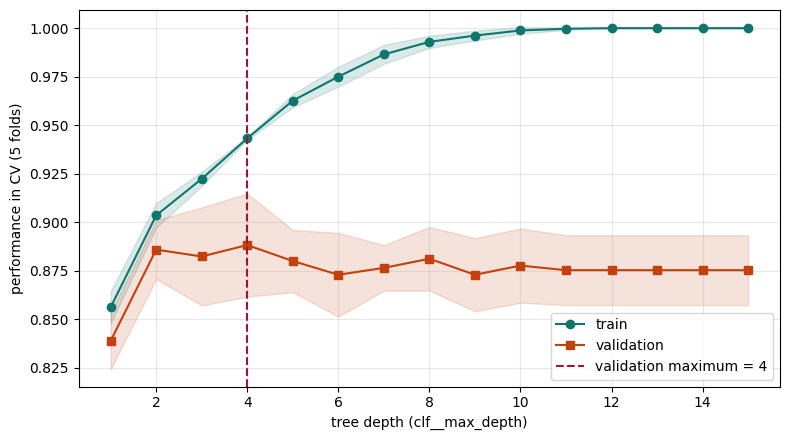

4

In [33]:
profundidades = list(range(1, 16))

# TODO: generate the validation curve for pipeline 'arvore' varying 'clf__max_depth'
tr, va = validation_curve(
    arvore, X, y,
    param_name="clf__max_depth",
    param_range=profundidades,
    cv=cv, scoring="accuracy")

m_tr, m_va, s_va = tr.mean(axis=1), va.mean(axis=1), va.std(axis=1)
plota_curva(profundidades, tr, va, "tree depth (clf__max_depth)")

## Part 2 — The Three Regions

Every well-behaved curve has three regions:

1. **Underfitting** (left) — low training **and** validation performance, small gap. The model is too simple.
2. **Optimal** (middle) — validation reaches its maximum.
3. **Overfitting** (right) — training performance rises towards 1.00, validation **stops improving**, and the **gap** (train − validation) grows.

Attention to the definition: **gap = train − validation, at the same hyperparameter value**. It is not the difference between two hyperparameter values, nor between validation and test.

### Example — The three depths table from Part 1

In [34]:
exemplo = pd.DataFrame({"depth": [1, 4, 15],
                        "train":     tr3.mean(axis=1).round(4),
                        "validation":  va3.mean(axis=1).round(4)})
exemplo["gap"] = (exemplo["train"] - exemplo["validation"]).round(4)
exemplo["interpretation"] = ["underfitting", "optimal", "overfitting"]
exemplo

,depth,train,validation,gap,interpretation
0,1,0.8562,0.8388,0.0174,underfitting
1,4,0.9432,0.8882,0.0550,optimal
2,15,1.0000,0.8753,0.1247,overfitting


### Exercise 2 — The Complete Table

Build a `DataFrame` with the 15 depths, columns `train`, `validation`, `std_dev` and `gap`, and sort **by validation**, from largest to smallest.

In [35]:
tabela = pd.DataFrame({"depth": profundidades,
                       "train":    m_tr.round(4),
                       "validation": m_va.round(4),
                       "std_dev":    s_va.round(4)})

# TODO: create the 'gap' column (train - validation) and sort by validation, descending
tabela["gap"] = (tabela["train"] - tabela["validation"]).round(4)
tabela = tabela.sort_values(by="validation", ascending=False)
tabela.head(6)

,depth,train,validation,std_dev,gap
3,4,0.9432,0.8882,0.0266,0.0550
1,2,0.9035,0.8859,0.0152,0.0176
2,3,0.9224,0.8824,0.0252,0.0400
7,8,0.9929,0.8812,0.0164,0.1117
4,5,0.9626,0.8800,0.0160,0.0826
9,10,0.9988,0.8776,0.0191,0.1212


## Part 3 — Choosing the Value and Measuring the Gap

The rule is always the same: **choose the value that maximizes validation**, never the one that maximizes training — that would always lead to the most complex model.

And whenever you report a chosen value, report **the gap at that point**. It is the most direct measure of overfitting, and almost no one includes it in reports.

### Example — Finding the maximum in a small vector

`argmax` returns the **position** of the maximum value, not the value itself. From this index, we retrieve the corresponding training, standard deviation, and hyperparameter values.

In [36]:
demo = np.array([0.80, 0.86, 0.84])
i_demo = int(np.argmax(demo))
print("maximum position:", i_demo, "| value:", demo[i_demo])

maximum position: 1 | value: 0.86


### Exercise 3 — The Choice and the Gap

Find the depth that **maximizes validation** and print, at that point, validation, training, standard deviation, and gap. Also print the gap at depth 15 for comparison.

In [37]:
# TODO: position of validation maximum
i = int(np.argmax(m_va))

melhor_prof = profundidades[i]
print("best depth          :", melhor_prof)
print("validation          :", round(m_va[i], 4))
print("train               :", round(m_tr[i], 4))
print("validation std dev  :", round(s_va[i], 4))
print("gap at chosen point :", round(m_tr[i] - m_va[i], 4))
print("gap at depth 15     :", round(m_tr[-1] - m_va[-1], 4))

best depth          : 4
validation          : 0.8882
train               : 0.9432
validation std dev  : 0.0266
gap at chosen point : 0.055
gap at depth 15     : 0.1247


## Part 4 — Is the Top a Peak or a Plateau?

The standard deviation across folds indicates how much that number fluctuates. If the difference between two hyperparameter values is **smaller than the standard deviation**, they tie within the error margin — and then the choice shifts to another criterion: the **simplest** model.

### Example — Comparing two values using standard deviation

In [38]:
a, b = 4, 2        # the two depths to compare
ia, ib = profundidades.index(a), profundidades.index(b)
dif = m_va[ia] - m_va[ib]
print(f"depth {a}: {m_va[ia]:.4f} ± {s_va[ia]:.4f}")
print(f"depth {b}: {m_va[ib]:.4f} ± {s_va[ib]:.4f}")
print(f"difference = {dif:.4f}   |   standard dev of best = {s_va[ia]:.4f}")
print("tie within error?", dif < s_va[ia])

depth 4: 0.8882 ± 0.0266
depth 2: 0.8859 ± 0.0152
difference = 0.0024   |   standard dev of best = 0.0266
tie within error? True


### Exercise 4 — Tie-breaking

Calculate the **floor** of the tie-breaking range (validation maximum minus one standard deviation at that point), list all depths that fall above it, and select the **simplest** (lowest) one in that range. Show the validation performance and the gap for the chosen depth.

In [39]:
# TODO: floor = validation maximum minus the standard deviation at that point
piso = m_va[i] - s_va[i]
dentro = [p for p, v in zip(profundidades, m_va) if v >= piso]

escolhida = min(dentro)          # TODO: the simplest one in the range
j = profundidades.index(escolhida)
print("floor of range     :", round(piso, 4))
print("inside the range   :", dentro)
print("chosen depth       :", escolhida)
print("validation / gap   :", round(m_va[j], 4), "/", round(m_tr[j] - m_va[j], 4))

floor of range     : 0.8617
inside the range   : [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
chosen depth       : 2
validation / gap   : 0.8859 / 0.0176


## Part 5 — Second Axis: the `C` of Logistic Regression

`C` controls **regularization**. Regularization is a brake: in addition to making few mistakes on training, the model is forced to keep coefficients small — a large coefficient is allowed only if it is highly beneficial.

`C` multiplies the **error term** in the optimization objective, not the penalty term. That is why it is inverted:
**small** `C` = strong brake = **simple** model; **large** `C` = weak brake = flexible model.

Because `C` varies by orders of magnitude, values are spaced on a **logarithmic** scale — and the plot axis is logarithmic too.

### Example — Why the axis must be logarithmic

See where the values fall on a linear scale: everything below 1 turns into a blur compressed next to zero.

values of C: [1.e-04 1.e-03 1.e-02 1.e-01 1.e+00 1.e+01 1.e+02 1.e+03]


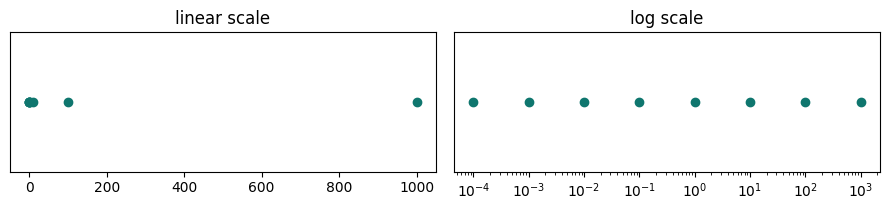

In [40]:
Cs = np.logspace(-4, 3, 8)
print("values of C:", Cs)

fig, ax = plt.subplots(1, 2, figsize=(9, 2.2))
for eixo, log in zip(ax, [False, True]):
    eixo.plot(Cs, np.zeros_like(Cs), "o", color="#0F766E")
    if log:
        eixo.set_xscale("log")
    eixo.set_title("log scale" if log else "linear scale")
    eixo.set_yticks([])
plt.tight_layout(); plt.show()

### Exercise 5 — The `C` Curve

Generate the validation curve for the `logistica` pipeline varying `clf__C` over these 8 values and plot it using `plota_curva`, remembering to set `log=True`.

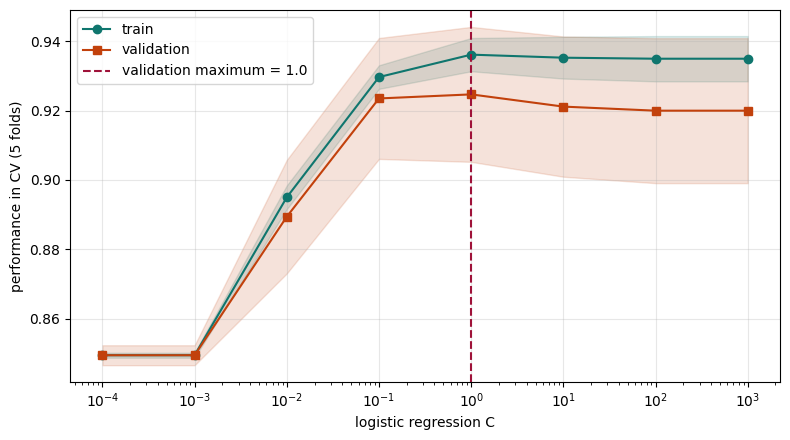

best C: 1.0 | validation: 0.9247


In [41]:
# TODO: generate validation curve for 'logistica' varying 'clf__C'
tr_c, va_c = validation_curve(
    logistica, X, y,
    param_name="clf__C",
    param_range=Cs,
    cv=cv, scoring="accuracy")

melhor_C = plota_curva(Cs, tr_c, va_c, "logistic regression C", log=True)
print("best C:", melhor_C, "| validation:", round(va_c.mean(axis=1).max(), 4))

## Part 6 — Accuracy's Blind Spot

The dataset has about 15% positive instances. In such an imbalanced dataset, accuracy has a blind spot: a baseline model that predicts "no one is at high risk" already achieves 0.8494 accuracy without looking at any patient.

### Example — Same model, two evaluation metrics

Look at the first point of the `C` curve (the most regularized model of all) evaluated using both metrics.

In [42]:
tr_f, va_f = validation_curve(
    logistica, X, y,
    param_name="clf__C", param_range=Cs,
    cv=cv, scoring="f1")

print(f"at C = 0.0001  ->  accuracy {va_c.mean(axis=1)[0]:.4f}   F1 {va_f.mean(axis=1)[0]:.4f}")

at C = 0.0001  ->  accuracy 0.8494   F1 0.0000


### Exercise 6 — The F1 Curve

Plot the `C` curve measured in **F1** and compare: does the chosen `C` change? What changes in the interpretation of the underfitting region?

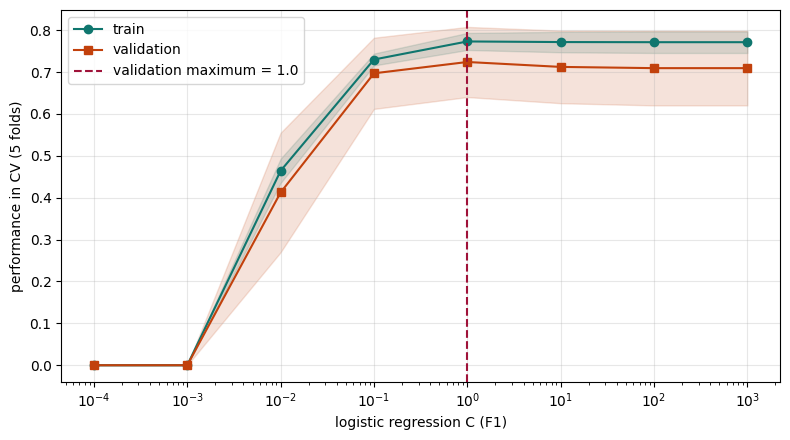

C = 0.0001    accuracy 0.8494   F1 0.0000
C = 0.001     accuracy 0.8494   F1 0.0000
C = 0.01      accuracy 0.8894   F1 0.4124
C = 0.1       accuracy 0.9235   F1 0.6969
C = 1         accuracy 0.9247   F1 0.7239
C = 10        accuracy 0.9212   F1 0.7122
C = 100       accuracy 0.9200   F1 0.7092
C = 1000      accuracy 0.9200   F1 0.7092


In [43]:
melhor_C_f1 = plota_curva(Cs, tr_f, va_f, "logistic regression C (F1)", log=True)

# TODO: print, side by side, validation performance in accuracy and F1 for each C
for c, a, f in zip(Cs, va_c.mean(axis=1), va_f.mean(axis=1)):
    print(f"C = {c:<8g}  accuracy {a:.4f}   F1 {f:.4f}")

## Part 7 — The Curve vs. Grid Search

A fair question: if `GridSearchCV` already scans multiple values, what is the purpose of the validation curve?

With only **one** hyperparameter, grid search with `return_train_score=True` returns identical numbers — in this case, the curve is just a convenience. The difference appears with **multiple** axes: `cv_results_` contains one row per *combination*, making the independent effect of one axis mixed with the others.

### Example — Searching on the same axis as Part 1

Note the `return_train_score=True`: without it, grid search **does not store** training scores — and without training scores, the gap cannot be measured.

In [44]:
busca = GridSearchCV(arvore, {"clf__max_depth": profundidades},
                     cv=cv, scoring="accuracy",
                     return_train_score=True).fit(X, y)

print("best_params_:", busca.best_params_)
print("best_score_ :", round(busca.best_score_, 4))

best_params_: {'clf__max_depth': 4}
best_score_ : 0.8882


### Exercise 7 — The Same Numbers?

Extract the training and validation means from `cv_results_` and verify if they match the ones obtained from the validation curve in Part 1.

In [46]:
res = pd.DataFrame(busca.cv_results_)

# TODO: compare the cv_results_ means with m_va and m_tr
print("validation matches?", np.allclose(res["mean_test_score"].values, m_va))
print("train matches?     ", np.allclose(res["mean_train_score"].values, m_tr))

validation matches? True
train matches?      True


---

**Congratulations!** You built two validation curves, read the three regions, measured the gap, used the
standard deviation to break ties, and saw accuracy's blind spot.

To apply this to your integrated project: run the curve on the two or three hyperparameters that matter **before**
performing a grid search — it is the curve that defines the range worth exploring — and, in your report, state the chosen value
**along with the gap at that specific point**.

In the **next lecture**: **learning** curves, where the x-axis represents the size of the training set.
The question shifts to: does more training data always help?